In [11]:
# License test code from Optimization Methods
# Import the packages needed to run the notebook
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import math

import gurobipy as gp
from gurobipy import *

In [12]:
# License test code from Optimization Methods
# Run this cell to test that your academic license works - you do not need to understand the model or submit anything
# from this cell for the project. If your academic license is **not** setup you will get an error: 
# GurobiError: Model too large for size-limited license
N = 100
c = np.random.rand(N,N)   

m0 = gp.Model('license_test')
x = m0.addVars(N,N, vtype=GRB.BINARY, name="x")     

for n in range(N):
    m0.addConstr(sum(x[n,j] for j in range(N)) == 1, name='row {}'.format(n))
    m0.addConstr(sum(x[i,n] for i in range(N)) == 1, name='col {}'.format(n))

m0.setObjective(sum(c[i,j] * x[i,j] for i in range(N) for j in range(N)), GRB.MINIMIZE)
m0.optimize()

Set parameter Username
Set parameter LicenseID to value 2878462
Academic license - for non-commercial use only - expires 2027-10-26
Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Optimize a model with 200 rows, 10000 columns and 20000 nonzeros
Model fingerprint: 0x92d6364d
Variable types: 0 continuous, 10000 integer (10000 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [2e-04, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]
Found heuristic solution: objective 52.3308350
Presolve time: 0.01s
Presolved: 200 rows, 10000 columns, 20000 nonzeros
Variable types: 0 continuous, 10000 integer (10000 binary)

Root relaxation: objective 1.658144e+00, 207 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth 

An online retailer is planning the locations of 3 fulfillment centers (FCs) that will be used over the next 20 years. The first FC will be opened immediately and will be the only operational FC for the next 6 years. After 6 years, a second FC will be opened and the retailer will operate the two FCs concurrently for another 5 years. After a total of 11 years, a third FC will be opened and all three FCs will be operational for another 9 years. The retailer would like to choose the locations of these three FCs.
In the attached spreadsheet, the first tab shows the x and y coordinates of the demand
points (DPs) that the online retailer serves. There are 20 DPs. Each DP is served by the
closest FC. The yearly cost of serving a DP from a certain FC is simply the Euclidean distance between the DP and the FC. The second tab shows the x and y coordinates of the possible locations for the FCs. There are 10 possible locations for FCs.
## (a) Formulate an integer programming model to choose the locations of the first, second and third FCs so that the total cost over the next 20 years is minimized.

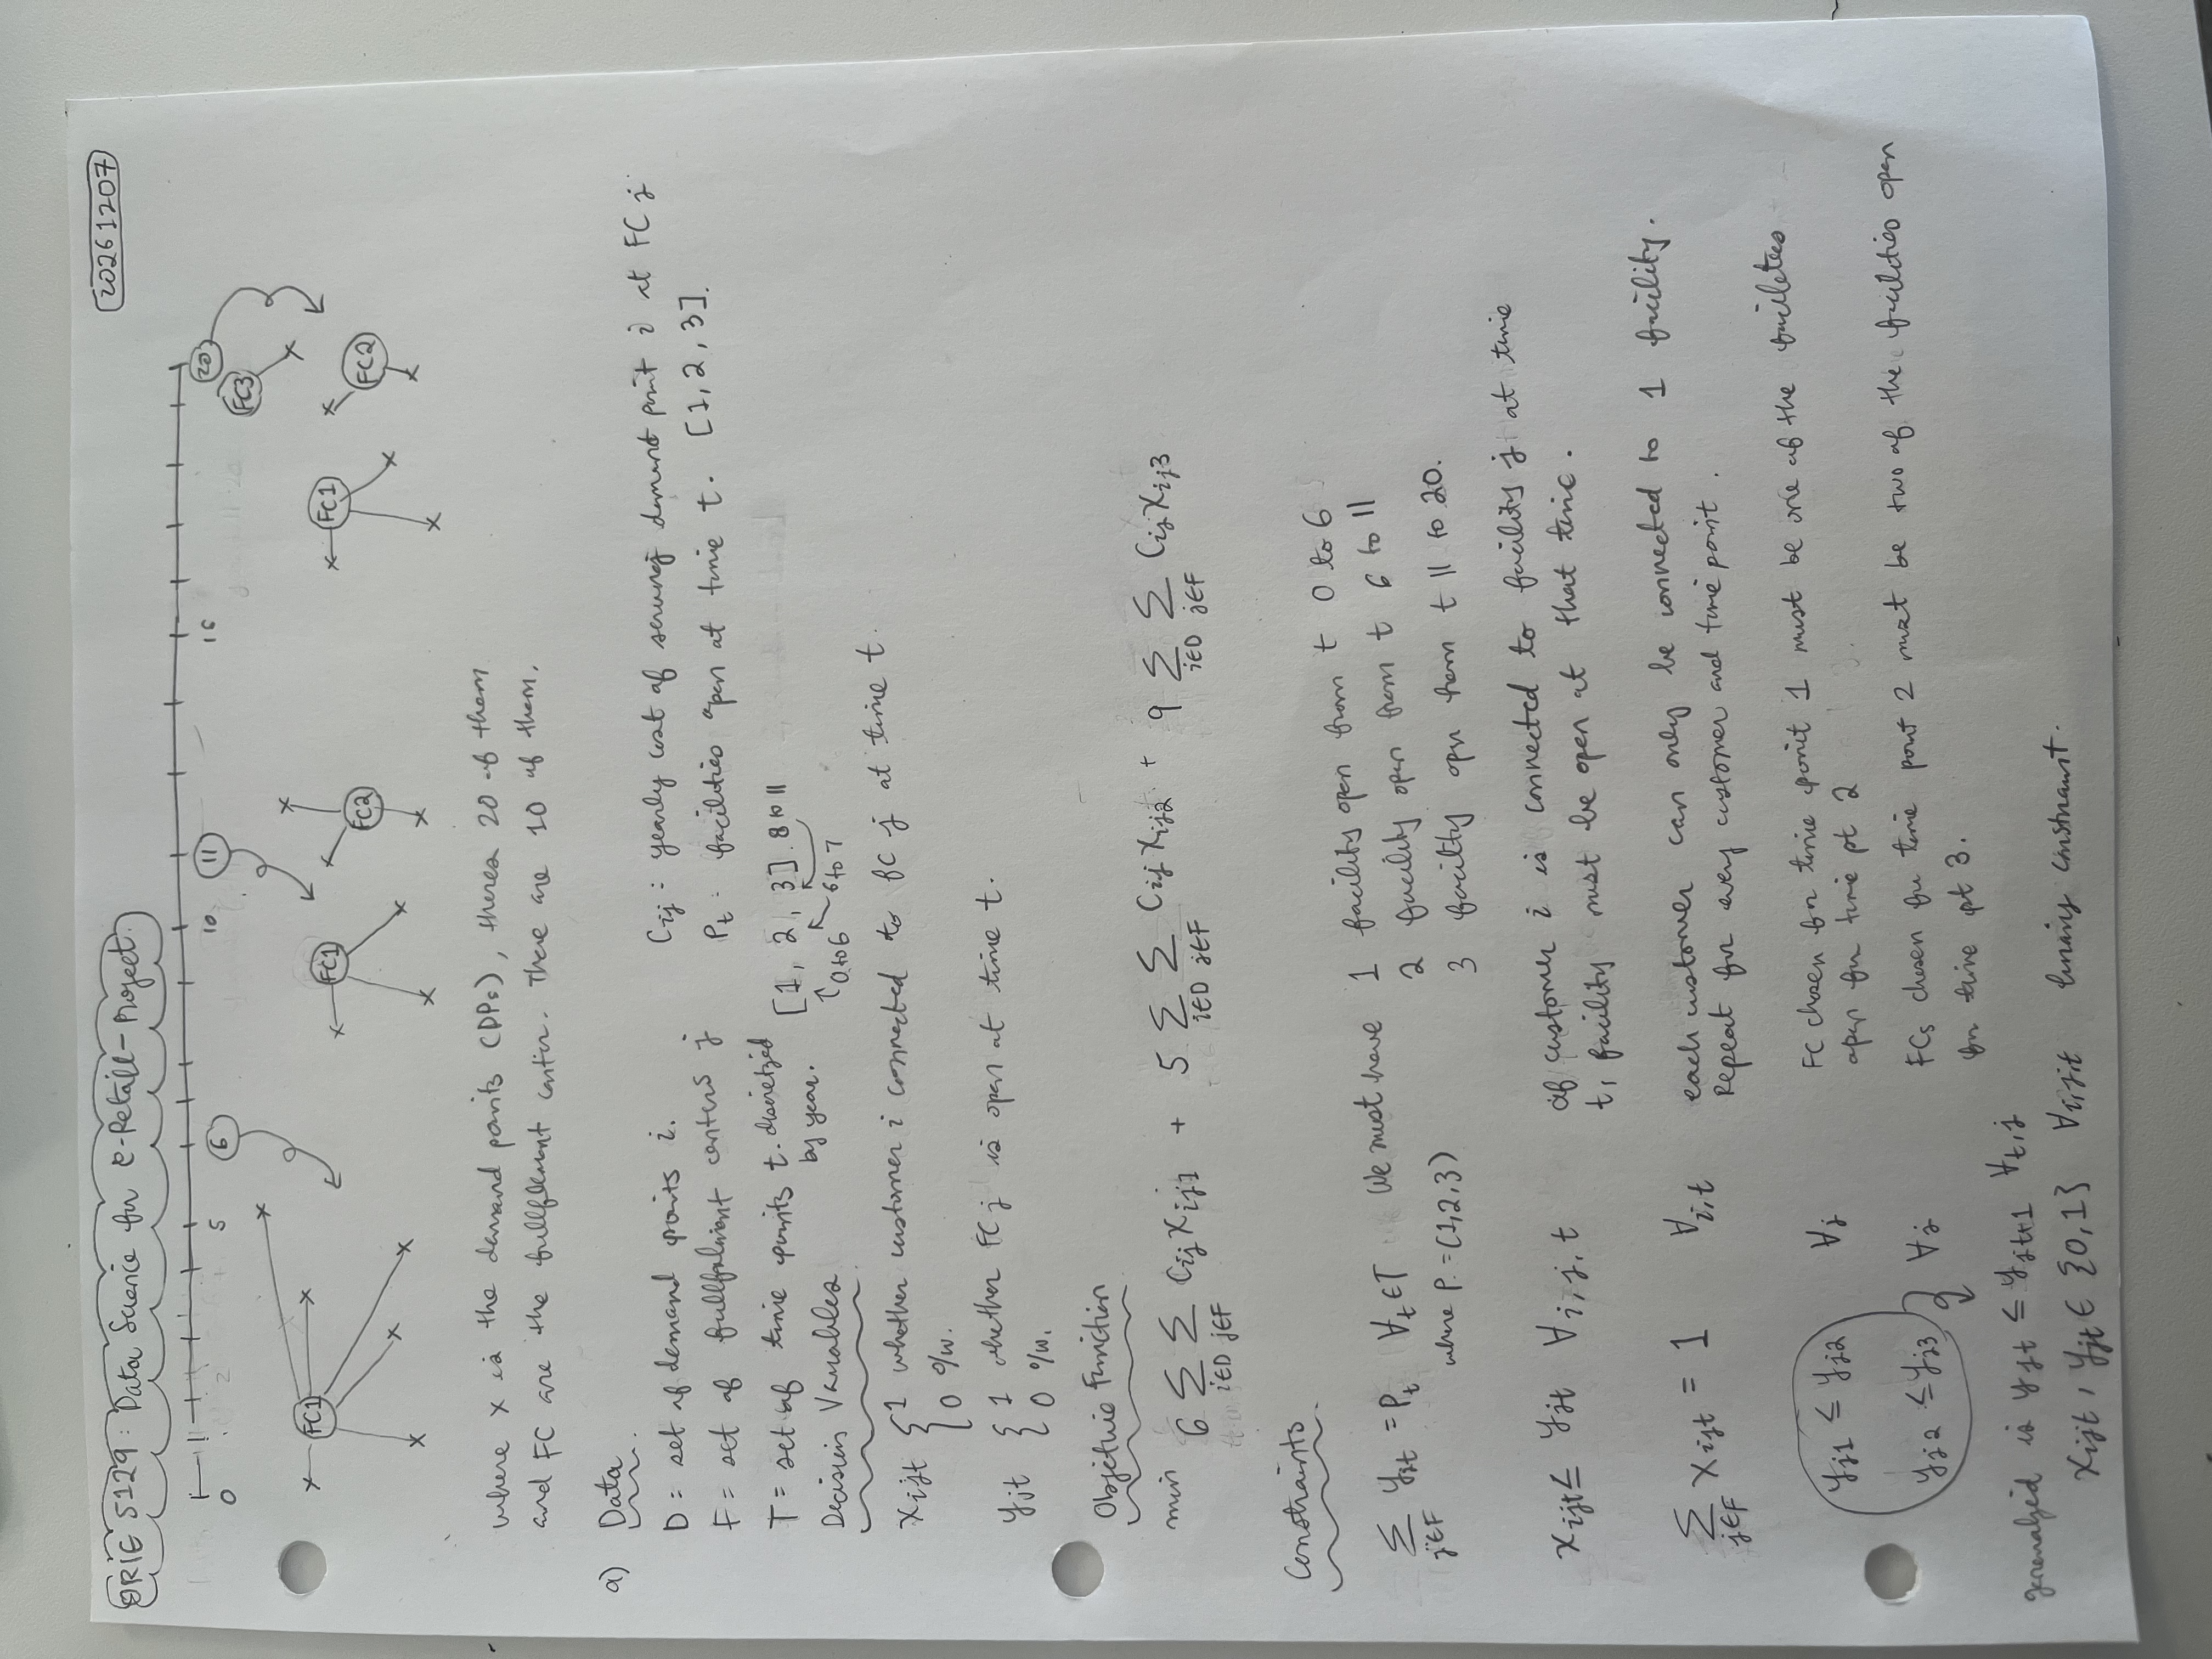

In [13]:
from IPython.display import Image, display
display(Image(filename="rl996_eretail_project.jpeg"))

## (b) Write a Python program that solves the integer programming model in Part a. 
* Accompanying the project description, there is a small Python program that you can use to plot the locations of your FCs and DPs, along with which DP is served by which FC. Use this Python program to give three plots. 
1. The first plot should show the location of the first FC and the assignment of DPs to the first FC. This is the situation faced by the company over the first 6 years. 
2. The second plot should show the locations of the first two FCs and the assignment of
DPs to the first two FCs. This is the situation faced by the company over the next 5 years.
3. Finally, the third plot should show the locations of all three FCs and the assignment of DPs to the three FCs. This is the situation faced by the company in the last 9 years.

In [14]:
# ---------------------------------------------------------------------------
# INITIALIZATION
# read data.xlsx: tab "DPs" has the x, y coordinates of the 20 demand points (set D)
#   and tab "FCs" has the x, y coordinates of the 10 candidate FC locations (set F)
# c_ij is the yearly cost of serving DP i from FC j = Euclidean distance
# T = {0, 1, 2} are the three periods (years 0-6, 6-11, 11-20)
#   P_t is the number of FCs open in period t and
#   w_t is the length of period t in years (weights in the objective)
# ---------------------------------------------------------------------------
def initializeData_b():
    dpsDf = pd.read_excel("data.xlsx", sheet_name="DPs")
    fcsDf = pd.read_excel("data.xlsx", sheet_name="FCs")

    dps_ = dpsDf[["x", "y"]].values.tolist()    # demand point coordinates
    fcs_ = fcsDf[["x", "y"]].values.tolist()    # candidate FC coordinates
    noDps_ = len(dps_)                          # |D| = 20
    noFcs_ = len(fcs_)                          # |F| = 10

    # 20 x 10 cost matrix, c_ij = distance between DP i and FC j
    cMatrix_ = [
        [math.dist(dps_[i], fcs_[j]) for j in range(noFcs_)]
        for i in range(noDps_)
    ]

    noPeriods_ = 3
    P_ = [1, 2, 3]      # number of FCs open in each period
    w_ = [6, 5, 9]      # years in each period (6 + 5 + 9 = 20)

    return (dps_, fcs_, noDps_, noFcs_, cMatrix_, noPeriods_, P_, w_)

In [15]:
# ---------------------------------------------------------------------------
# CONSTRUCT VARIABLES
# binary variables x_ijt = 1 if DP i is served by FC j in period t
# binary variables y_jt  = 1 if FC j is open in period t
# the binary constraint is defined here with vtype=GRB.BINARY
# ---------------------------------------------------------------------------
def constructVars_b():
    global ipModel, xVars, yVars

    xVars = ipModel.addVars(noDps_, noFcs_, noPeriods_, vtype=GRB.BINARY, name="x")
    yVars = ipModel.addVars(noFcs_, noPeriods_, vtype=GRB.BINARY, name="y")

    ipModel.update()

In [16]:
# ---------------------------------------------------------------------------
# CONSTRUCT OBJECTIVE FUNCTION
# minimize total cost over 20 years:
#   min  6 sum_i sum_j c_ij x_ij0 + 5 sum_i sum_j c_ij x_ij1 + 9 sum_i sum_j c_ij x_ij2
#      = sum_t w_t sum_i sum_j c_ij x_ijt
# ---------------------------------------------------------------------------
def constructObj_b():
    objExpr = LinExpr()
    for t in range(noPeriods_):
        for i in range(noDps_):
            for j in range(noFcs_):
                objExpr += w_[t] * cMatrix_[i][j] * xVars[i, j, t]
    ipModel.setObjective(objExpr, GRB.MINIMIZE)
    ipModel.update()

In [17]:
# ---------------------------------------------------------------------------
# CONSTRUCT CONSTRAINTS
#   (1) cardinality: sum_j y_jt = P_t for every period t
#         (1 FC open in years 0-6, 2 in years 6-11, 3 in years 11-20)
#   (2) assignment: sum_j x_ijt = 1 for every DP i and period t
#         (every DP is served by exactly one FC in every period)
#   (3) linking: x_ijt <= y_jt for every i, j, t
#         (a DP can only be served by an FC that is open)
#   (4) nesting: y_jt <= y_j,t+1 for every j and t = 0, 1
#         (once an FC is opened it stays open)
# no constraint is needed for "served by the closest FC": with no capacities,
#   minimizing cost automatically assigns each DP to its closest open FC
# ---------------------------------------------------------------------------
def constructConsts_b():

    for t in range(noPeriods_):
        constrExpr = LinExpr()
        for j in range(noFcs_):
            constrExpr += yVars[j, t]
        ipModel.addLConstr(lhs=constrExpr, sense=GRB.EQUAL, rhs=P_[t], name="cardinality_" + str(t))

    for i in range(noDps_):
        for t in range(noPeriods_):
            constrExpr = LinExpr()
            for j in range(noFcs_):
                constrExpr += xVars[i, j, t]
            ipModel.addLConstr(lhs=constrExpr, sense=GRB.EQUAL, rhs=1, name="assignment_" + str(i) + "_" + str(t))

    for i in range(noDps_):
        for j in range(noFcs_):
            for t in range(noPeriods_):
                ipModel.addLConstr(lhs=xVars[i, j, t], sense=GRB.LESS_EQUAL, rhs=yVars[j, t], name="linking_" + str(i) + "_" + str(j) + "_" + str(t))

    for j in range(noFcs_):
        for t in range(noPeriods_ - 1):
            ipModel.addLConstr(lhs=yVars[j, t], sense=GRB.LESS_EQUAL, rhs=yVars[j, t + 1], name="nesting_" + str(j) + "_" + str(t))

    ipModel.update()

In [18]:
# ---------------------------------------------------------------------------
# PRINT SOLUTIONS
# print the optimal objective value, which FCs are open in each period,
#   and which FC serves each DP in each period
# returns openFcs[t] (list of open FCs) and assgns[t] (FC serving each DP)
# ---------------------------------------------------------------------------
def printSolution_b():
    print("Opt. Obj. " + str(ipModel.ObjVal))
    periodNames = ["years 0-6", "years 6-11", "years 11-20"]
    openFcs = []
    assgns = []
    for t in range(noPeriods_):
        openFcs.append([j for j in range(noFcs_) if yVars[j, t].x > 0.5])
        assgns.append([next(j for j in range(noFcs_) if xVars[i, j, t].x > 0.5) for i in range(noDps_)])
        periodCost = sum(cMatrix_[i][assgns[t][i]] for i in range(noDps_))
        print("Period " + str(t + 1) + " (" + periodNames[t] + "): open FCs " + str(openFcs[t])
              + ", yearly cost " + str(round(periodCost, 2)))
        print("   DP -> FC: " + str(assgns[t]))
    return openFcs, assgns

In [19]:
# ---------------------------------------------------------------------------
# PLOT
# plotting code adapted from FacilityPlot.py: open FCs in green, DPs in red,
#   and a black line from each DP to the FC that serves it
# candidate FC locations that are not open are shown as grey circles
# ---------------------------------------------------------------------------
def plotPeriod_b(openFcs, assgns, title):
    plt.figure(figsize=(6, 6))

    for fc in range(noFcs_):
        if fc not in openFcs:
            plt.plot(fcs_[fc][0], fcs_[fc][1], 'o', color="lightgrey", markersize=8)

    for dp in range(noDps_):
        dpx = dps_[dp][0]
        dpy = dps_[dp][1]
        fcx = fcs_[assgns[dp]][0]
        fcy = fcs_[assgns[dp]][1]
        plt.plot([dpx, fcx], [dpy, fcy], color="black")

    for dp in range(noDps_):
        plt.plot(dps_[dp][0], dps_[dp][1], 'o', color="red")

    for fc in openFcs:
        plt.plot(fcs_[fc][0], fcs_[fc][1], 'o', color="green", markersize=12)
        plt.annotate("FC " + str(fc), (fcs_[fc][0], fcs_[fc][1]), textcoords="offset points", xytext=(8, 8))

    plt.title(title)
    plt.xlim(-5, 105)
    plt.ylim(-5, 105)
    plt.show()

In [20]:
# ---------------------------------------------------------------------------
# RUNNING COMPUTATION
# initializes the data, constructs the model, and writes the model to a file
# ---------------------------------------------------------------------------
(dps_, fcs_, noDps_, noFcs_, cMatrix_, noPeriods_, P_, w_) = initializeData_b()
ipModel = gp.Model("fulfillment_centers")
constructVars_b()
constructObj_b()
constructConsts_b()
ipModel.write("fulfillment_centers.lp")

/Users/leo/Library/Python/3.9/lib/python/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/Users/leo/Library/Python/3.9/lib/python/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[arm] - Darwin 24.6.0 24G720)

CPU model: Apple M4
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Optimize a model with 683 rows, 630 columns and 1870 nonzeros
Model fingerprint: 0x5a0139ad
Variable types: 0 continuous, 630 integer (630 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [2e+01, 1e+03]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+00]
Presolve removed 220 rows and 200 columns
Presolve time: 0.01s
Presolved: 463 rows, 430 columns, 1270 nonzeros
Variable types: 0 continuous, 430 integer (430 binary)
Found heuristic solution: objective 15845.354409

Root relaxation: objective 1.276015e+04, 210 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

*    0     0               0    12760.151023 12760.

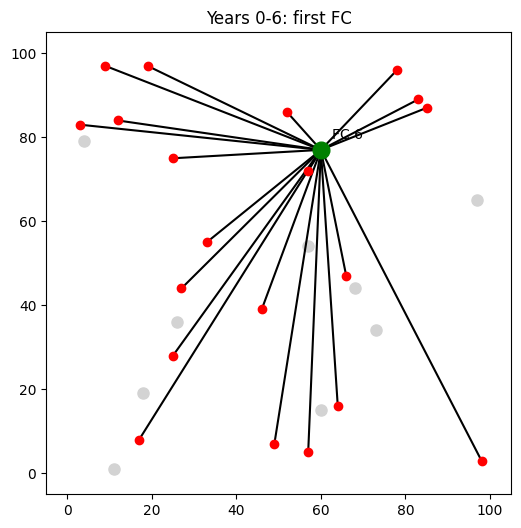

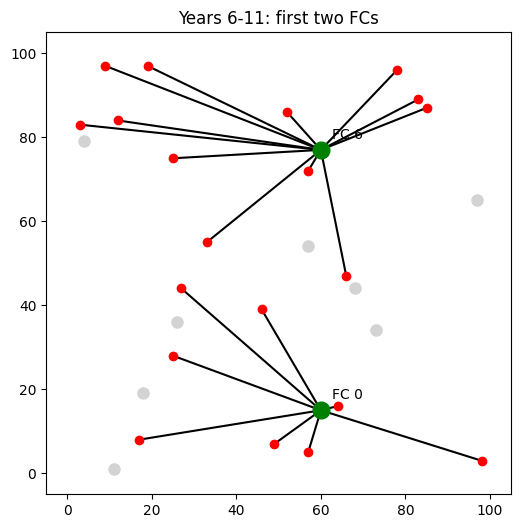

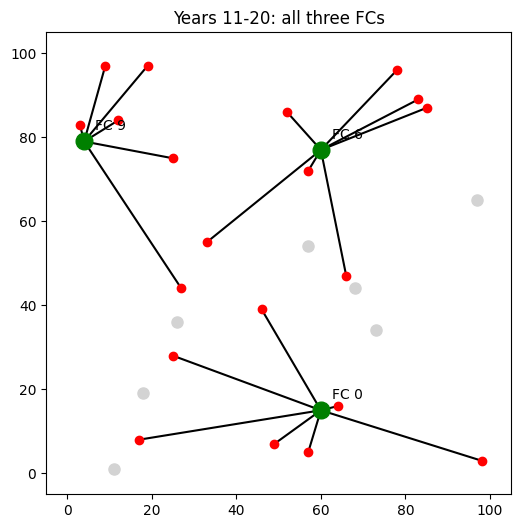

In [21]:
# ---------------------------------------------------------------------------
# OPTIMIZE!
# optimize the model, print the solution, and make the three plots
# ---------------------------------------------------------------------------
ipModel.optimize()
openFcs, assgns = printSolution_b()

plotPeriod_b(openFcs[0], assgns[0], "Years 0-6: first FC")
plotPeriod_b(openFcs[1], assgns[1], "Years 6-11: first two FCs")
plotPeriod_b(openFcs[2], assgns[2], "Years 11-20: all three FCs")